# EIL PINN — Train on Makilala → Predict on whole North Cotabato

Interactive version of the `pinn_eil` pipeline (`run_training.py` + `train.py` + `predict_map_polygons.py`).

The network **is** the solution `u(z, t)` of the 1D nonlinear elasto-plastic wave equation for a soil column, trained purely by driving the physics **residuals** (PDE / Bouc-Wen ODE / BC / IC) to zero via `tf.GradientTape` automatic differentiation — **there are no displacement labels**.

**Workflow:** train the amortized network **once on Makilala** (18,145 units, driven by the real 2019 M6.7 Cotabato SPECFEM base motion), then run **inference over the whole North Cotabato area** (285,644 units from `outputs/su_19_v1_contri_susceptibility.gpkg`). The earthquake enters **only during training**; inference just queries `NN(z, t, rho, k, eps_y, H, pga)` at the surface — so **no NC-specific base motion is needed**. The Makilala model normalizes NC inputs with its own baked-in ranges; NC values outside Makilala's training ranges are extrapolated.

Build the NC conditioning once (per-unit `rho, k, eps_y, H, pga` — *not* base motion): `venv/bin/python -m pinn_wave.build_nc_dataset`.

Sections:
1. Build the model via the **`EILPinn` builder class** (`__init__` config → `build_model()` → `get_optimizer()`).
2. Curriculum configuration (5s → 10s → 20s → full T).
3. Train on **Makilala**.
4. Save the trained model to `pinn_eil/checkpoints/pinn_makilala.keras`.
5. 3D loss-term ribbon chart (PDE highlighted).
6. **Inference over the whole North Cotabato area** → `nc_cotabato_pinn_displacement.gpkg` + map.

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

# notebooks/ sits one level below the repo root; put the root on sys.path so `pinn_eil` imports.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.environ['TF_DETERMINISTIC_OPS'] = '1'

# TRAIN on Makilala (its SPECFEM base motion + normalization ranges); then run INFERENCE over the
# WHOLE North Cotabato area in section 6. We leave PINN_EIL_DATASET unset (defaults to 'makilala'),
# and load the NC conditioning explicitly for inference via load_unit_table(data_prefix='nc_cotabato').
# The earthquake enters ONLY during training -- inference just queries NN(z,t,rho,k,eps_y,H,pga) --
# so no NC-specific base motion is needed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Importing the package registers the custom AmortizedNormalization layer (needed for save/load).
import pinn_eil as P
from pinn_eil import config as CFG
from pinn_eil import train as T

tf.keras.utils.set_random_seed(0)

OUTPUTS_DIR = PROJECT_ROOT / 'pinn_eil' / 'outputs'
MODELS_DIR = CFG.CHECKPOINT_PATH.parent                       # pinn_eil/checkpoints
MODEL_PATH = CFG.CHECKPOINT_PATH                              # pinn_makilala.keras (default)
HIST_PATH = OUTPUTS_DIR / f'training_history_{CFG.MODEL_PREFIX}.csv'
PLOT_PNG = OUTPUTS_DIR / f'pinn_eil_loss_evolution_3d_{CFG.MODEL_PREFIX}.png'

# --- North Cotabato inference target (285,644 units) --------------------------------------------
# Built once by:  venv/bin/python -m pinn_wave.build_nc_dataset
NC_PREFIX = 'nc_cotabato'
NC_COND_GPKG = CFG.PINN_WAVE_DATA / f'{NC_PREFIX}_pinn_conditioning.gpkg'
NC_OUT_GPKG = OUTPUTS_DIR / f'{NC_PREFIX}_pinn_displacement.gpkg'
NC_OUT_PNG = OUTPUTS_DIR / f'{NC_PREFIX}_pinn_displacement_map_polygons.png'

print('project root :', PROJECT_ROOT)
print('train dataset:', CFG.DATASET, '| model ->', MODEL_PATH.name)
print('infer target :', NC_PREFIX, '| gpkg present:', NC_COND_GPKG.exists())

project root : /Users/giogonzales/Documents/ml-prep/mlprep
train dataset: makilala | model -> pinn_makilala.keras
infer target : nc_cotabato | gpkg present: True


## 2. Build the model (`EILPinn` builder-class chain)

Cotabato production paradigm: instantiate the config-holding builder, `build_model()` assembles the Functional graph onto `self.model`, and `get_optimizer()` stores the Adam + ExponentialDecay optimizer on `self.optimizer_instance`.

In [2]:
ranges = P.load_norm_ranges()
consts = P.load_global_consts()
scales = P.load_scales(consts)
sampler = P.UnitSampler(consts.T, seed=0)

builder = P.EILPinn(ranges, consts.T)
builder.build_model()             # -> builder.model (Functional graph)
builder.get_optimizer(lr=1e-3)    # -> builder.optimizer_instance (Adam + ExponentialDecay)
model = builder.model

print(f'[setup] units={sampler._n_units} params={model.count_params()} '
      f'u_scale={consts.u_scale:.4e} T={consts.T}')
print(f'[setup] optimizer={type(builder.optimizer_instance).__name__}')
model.summary()

[setup] units=18145 params=17282 u_scale=4.9963e-02 T=40.0
[setup] optimizer=Adam


Model: "pinn_eil"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ physical_inputs     │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ amortized_normaliz… │ (None, 7)         │          0 │ physical_inputs[… │
│ (AmortizedNormaliz… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_0 (Dense)    │ (None, 64)        │        512 │ amortized_normal… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_1 (Dense)    │ (None, 64)        │      4,160 │ hidden_0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_2 (Dense)    │ (None, 64)        │      4,160 │ hidden_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_3 (Dense)    │ (None, 64)        │      4,160 │ hidden_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_4 (Dense)    │ (None, 64)        │      4,160 │ hidden_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ phi (Dense)         │ (None, 1)         │         65 │ hidden_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ u (Dense)           │ (None, 1)         │         65 │ hidden_4[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,282 (67.51 KB)

 Trainable params: 17,282 (67.51 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Curriculum configuration

Time-window curriculum ported from `run_training.py`: train on growing time windows so the network learns the initial pulse first, then extends through the ringdown. The full run is **5400 epochs** (1200 + 1200 + 1200 + 1800). Set `SCALE < 1` for a quick smoke run (e.g. `SCALE = 0.05`).

In [3]:
SCALE = 1.0   # epoch multiplier; e.g. 0.05 for a fast smoke run

stages = [
    (5.0, int(1200 * SCALE)),
    (10.0, int(1200 * SCALE)),
    (20.0, int(1200 * SCALE)),
    (consts.T, int(1800 * SCALE)),
]
print('stages (t_max, epochs):', stages)
print('total epochs:', sum(e for _, e in stages))

stages (t_max, epochs): [(5.0, 1200), (10.0, 1200), (20.0, 1200), (40.0, 1800)]
total epochs: 5400


## 4. Train (physics-residual curriculum)

Passes `builder.optimizer_instance` into the curriculum so the builder-configured optimizer is the one actually used across all stages.

In [4]:
history = T.train_curriculum(
    model, consts, scales, sampler,
    stages=stages,
    optimizer=builder.optimizer_instance,
    n_col=4000, n_bc=1000, n_ic=1000,
    resample_every=100, log_every=200,
)
print(f'\n[final] loss={history[-1]["loss"]:.4e}')


=== curriculum stage 1/4: t in [0, 5s], 1200 epochs ===
epoch      0 | L=2.6852e+00 | pde=9.528e-01 bw=1.318e-03 base=2.832e-03 surf=8.970e-03 ic_u=7.381e-02 ic_ut=8.451e-02 ic_phi=2.986e-03
epoch    200 | L=8.5981e-01 | pde=7.743e-01 bw=2.477e-04 base=1.356e-03 surf=3.285e-03 ic_u=3.137e-03 ic_ut=9.703e-06 ic_phi=7.429e-04
epoch    400 | L=7.1526e-01 | pde=6.280e-01 bw=3.178e-04 base=5.549e-04 surf=4.763e-04 ic_u=7.366e-03 ic_ut=2.073e-05 ic_phi=2.788e-04
epoch    600 | L=7.0130e-01 | pde=5.776e-01 bw=2.616e-04 base=1.778e-03 surf=1.553e-03 ic_u=8.664e-03 ic_ut=2.277e-05 ic_phi=3.232e-04
epoch    800 | L=6.8552e-01 | pde=5.631e-01 bw=2.118e-04 base=1.268e-03 surf=1.551e-03 ic_u=8.989e-03 ic_ut=1.505e-05 ic_phi=3.957e-04
epoch   1000 | L=6.7133e-01 | pde=5.364e-01 bw=2.835e-04 base=1.081e-03 surf=1.097e-03 ic_u=1.085e-02 ic_ut=1.481e-05 ic_phi=4.168e-04
epoch   1199 | L=6.3845e-01 | pde=4.963e-01 bw=2.956e-04 base=1.548e-03 surf=2.667e-03 ic_u=9.543e-03 ic_ut=1.826e-05 ic_phi=4.120e-0

## 5. Save model + history

Model → `pinn_eil/checkpoints/pinn_makilala.keras` (dataset-aware `CFG.CHECKPOINT_PATH`); loss history → `pinn_eil/outputs/training_history_makilala.csv`. Saved under `checkpoints/` (not `outputs/models/`) so `run_training.py` / `predict_map*.py` load the same file.

In [5]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model.save(MODEL_PATH)
pd.DataFrame(history).to_csv(HIST_PATH, index=False)
print('[saved]', MODEL_PATH)
print('[saved]', HIST_PATH)

[saved] /Users/giogonzales/Documents/ml-prep/mlprep/pinn_eil/checkpoints/pinn_makilala.keras
[saved] /Users/giogonzales/Documents/ml-prep/mlprep/pinn_eil/outputs/training_history_makilala.csv


## 6. 3D loss-term ribbon plot

Shows how each physics residual evolves over training. **X** = epoch, **Y** = residual term, **Z** = `log10(scaled loss)`. The **PDE** ribbon is highlighted because it is the stiff, gravity/stiffness-dominated term that drives overall convergence.

Note: the seven component terms (`pde, bw, base, surf, ic_u, ic_ut, ic_phi`) are the **un-weighted** scaled residual MSEs; the `loss` column is the **weighted** total (`w_pde·pde + w_bw·bw + w_bc·(base+surf) + w_ic·(ic_u+ic_ut+ic_phi)`), so the components will not sum to `loss`. This plot can also be regenerated from the saved `training_history.csv` alone (no retraining needed) — the fallback below loads it if `history` is not in memory.

/var/folders/dz/wrg2699d4jq7zd26swc8s2wm0000gn/T/ipykernel_56657/1401376529.py:45: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


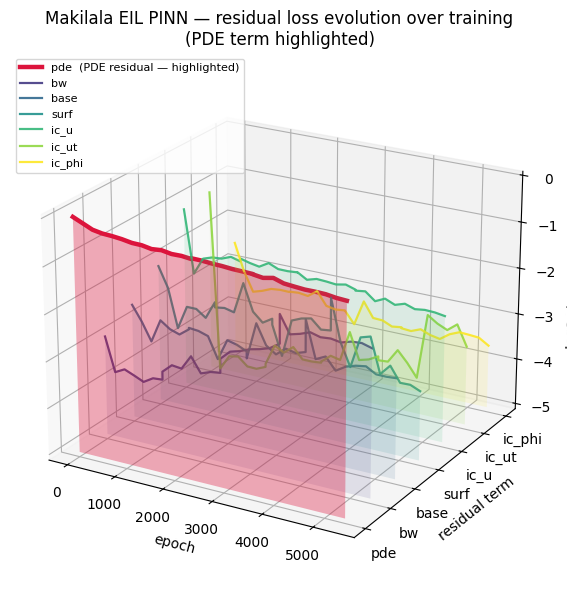

[saved] /Users/giogonzales/Documents/ml-prep/mlprep/pinn_eil/outputs/pinn_eil_loss_evolution_3d_makilala.png


In [6]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Use the in-memory history if present, else replay from the saved CSV.
try:
    df = pd.DataFrame(history)
except NameError:
    df = pd.read_csv(HIST_PATH)

TERMS = ['pde', 'bw', 'base', 'surf', 'ic_u', 'ic_ut', 'ic_phi']
FLOOR = 1e-12   # positive floor before log10 (guards zeros / tiny values)
epoch = df['epoch'].to_numpy()
logz = {t: np.log10(np.clip(df[t].to_numpy(), FLOOR, None)) for t in TERMS}
z_base = min(v.min() for v in logz.values())   # shared baseline for the filled ribbons

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')
cmap = plt.get_cmap('viridis')

for i, t in enumerate(TERMS):
    z = logz[t]
    is_pde = (t == 'pde')
    color = 'crimson' if is_pde else cmap(i / (len(TERMS) - 1))
    # filled ribbon from the shared baseline up to the curve (waterfall look)
    verts = ([(epoch[0], i, z_base)]
             + list(zip(epoch, [i] * len(epoch), z))
             + [(epoch[-1], i, z_base)])
    poly = Poly3DCollection([verts], facecolor=color, edgecolor='none',
                            alpha=0.35 if is_pde else 0.12)
    ax.add_collection3d(poly)
    # curve on top
    ax.plot(epoch, [i] * len(epoch), z, color=color,
            linewidth=3.2 if is_pde else 1.6,
            alpha=1.0 if is_pde else 0.9,
            label=('pde  (PDE residual — highlighted)' if is_pde else t))

ax.set_yticks(range(len(TERMS)))
ax.set_yticklabels(TERMS)
ax.set_xlabel('epoch')
ax.set_ylabel('residual term')
ax.set_zlabel('log10(scaled loss)')
ax.set_title('Makilala EIL PINN — residual loss evolution over training\n'
             '(PDE term highlighted)')
ax.view_init(elev=22, azim=-60)
ax.legend(loc='upper left', fontsize=8)
fig.tight_layout()
fig.savefig(PLOT_PNG, dpi=150, bbox_inches='tight')
plt.show()
print('[saved]', PLOT_PNG)

## 6. Inference over the whole North Cotabato area

Reuse the just-trained **Makilala** `model` (no retraining). Load the 285,644 NC units' conditioning `(rho, k, eps_y, H, pga)` explicitly via `load_unit_table(data_prefix='nc_cotabato')`, query the network at the surface (`z = H`) over `[0, T]`, and take the peak `|u|` per unit — the displacement-hazard metric. The Makilala model normalizes NC inputs with its own baked-in ranges (NC values outside Makilala's training ranges are extrapolated).

Writes `pinn_eil/outputs/nc_cotabato_pinn_displacement.gpkg` (285k polygons, WGS84, per-unit `peak_disp_mm`) + a polygon map — the whole-NC analogue of the reference `su_19_v1_contri_susceptibility.gpkg`.

In [7]:
import geopandas as gpd
from pinn_eil.predict_map import peak_surface_displacement

# NC conditioning rows (positionally aligned with the NC polygon gpkg; unit_id is NOT unique).
nc_table = P.load_unit_table(data_prefix=NC_PREFIX)      # 285,644 NC units
nc_gdf = gpd.read_file(NC_COND_GPKG)
assert np.array_equal(nc_gdf['unit_id'].to_numpy(), nc_table['unit_id'].to_numpy()), \
    'NC gpkg and unit table are not row-aligned; cannot attach positionally'

# `consts` (T, u_scale) come from the Makilala/shared base motion — same earthquake, so valid for NC.
peaks = peak_surface_displacement(model, consts, nc_table)   # physical metres, relative to base
nc_out = nc_gdf.assign(peak_disp_m=peaks, peak_disp_mm=peaks * 1000.0).to_crs(epsg=4326)
nc_out.to_file(NC_OUT_GPKG, driver='GPKG')

print(f'[NC infer] model={MODEL_PATH.name} -> {len(nc_out)} NC units')
print(f'[NC infer] peak disp (mm): min={peaks.min()*1000:.2f} '
      f'med={np.median(peaks)*1000:.2f} max={peaks.max()*1000:.2f}')
print('[saved]', NC_OUT_GPKG)

[NC infer] model=pinn_makilala.keras -> 285644 NC units
[NC infer] peak disp (mm): min=3.11 med=11.19 max=14.86
[saved] /Users/giogonzales/Documents/ml-prep/mlprep/pinn_eil/outputs/nc_cotabato_pinn_displacement.gpkg


In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 8.5))
nc_out.plot(column='peak_disp_mm', cmap='inferno_r', linewidth=0.0, ax=ax, legend=True,
            legend_kwds={'label': 'Peak surface displacement [mm]', 'shrink': 0.85})
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal', adjustable='datalim')
ax.set_title('North Cotabato EIL PINN — predicted peak surface displacement per slope unit\n'
             '(Makilala-trained model; 2019 M6.7 Cotabato base motion, scaled per unit by PGA)')
fig.tight_layout()
fig.savefig(NC_OUT_PNG, dpi=150)
plt.show()
print('[saved]', NC_OUT_PNG)

/var/folders/dz/wrg2699d4jq7zd26swc8s2wm0000gn/T/ipykernel_56657/3325971052.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


[saved] /Users/giogonzales/Documents/ml-prep/mlprep/pinn_eil/outputs/nc_cotabato_pinn_displacement_map_polygons.png
